# Introduction to Machine Learning – Lab 3
## k-Means Clustering with Log-Transformed Features and Z-Score Scaling

### Objective
This notebook combines the two changes tested before: the logarithm of notebook 08.2 and the z-score scaling of notebook 08.1. Comparing it with notebook 08.1 shows what the logarithm adds when the data is z-scored.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import numpy as np
import pandas as pd
from clustering import (
    N_INIT,
    SEED,
    agreement_table,
    fit_models,
    inertia_table,
    plot_clusters,
    plot_elbow,
    plot_silhouettes,
    reduce_to_thresholds,
    silhouette_table,
    variance_by_type,
)
from preprocessing import (
    LOG_FEATURES,
    ORDINAL,
    drop_incomplete,
    fill_missing,
    log_features,
    make_preprocessor,
    make_zscore_scaler,
    prepare_data,
)
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_samples

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

### Data preparation
The houses are loaded, the two houses with whole blocks of empty cells are dropped, the remaining gaps are filled and the categorical features are encoded. Notebook 08 explains these choices.

In [2]:
X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
X_complete, y_complete = drop_incomplete(X, y)
X_complete = fill_missing(X_complete)
encoded_complete = make_preprocessor("onehot", min_frequency=5).fit_transform(X_complete, y_complete)

onehot = [col for col in encoded_complete.columns if col not in X_complete.columns]
ordinal = [col for col in encoded_complete.columns if col in ORDINAL]
numeric = [col for col in encoded_complete.columns if col not in onehot + ordinal]
column_types = {"One-hot": onehot, "Ordinal": ordinal, "Numeric": numeric}

assert encoded_complete.isna().sum().sum() == 0
assert len(onehot) + len(ordinal) + len(numeric) == encoded_complete.shape[1]

print(f"{len(encoded_complete):,} houses, {encoded_complete.shape[1]} columns")
print(f"One-hot: {len(onehot)}, ordinal: {len(ordinal)}, numeric: {len(numeric)}")

2,923 houses, 205 columns
One-hot: 151, ordinal: 21, numeric: 33


### Log transform and z-score scaling
Two choices are taken over here without testing them again. Notebook 08.2 tests which columns get a logarithm and why it has to come before the scaling. Notebook 08.1 tests whether z-score scaling should touch the one-hot columns and keeps them at 0/1.

In [3]:
columns = encoded_complete.columns
scaled_columns = ordinal + numeric

# Fitted on all houses: k-means has no train/test split.
# The transformer moves the scaled columns to the front, so the original order is restored
logged = log_features(encoded_complete)
scaled = make_zscore_scaler(scaled_columns).fit_transform(logged)[columns]
scaled_without_log = make_zscore_scaler(scaled_columns).fit_transform(encoded_complete)[columns]

assert scaled[onehot].equals(encoded_complete[onehot])
assert np.allclose(scaled[scaled_columns].mean(), 0) and np.allclose(scaled[scaled_columns].std(ddof=0), 1)

variance_shares = pd.DataFrame(
    {"Without log": variance_by_type(scaled_without_log, column_types), "With log": variance_by_type(scaled, column_types)}
).T
log_columns = pd.DataFrame(
    {
        "Variance without log": scaled_without_log[LOG_FEATURES].var(ddof=0),
        "Variance with log": scaled[LOG_FEATURES].var(ddof=0),
        "Skew without log": scaled_without_log[LOG_FEATURES].skew(),
        "Skew with log": scaled[LOG_FEATURES].skew(),
        "Largest value without log": scaled_without_log[LOG_FEATURES].max(),
        "Largest value with log": scaled[LOG_FEATURES].max(),
    }
)

print("Share of the total variance by column type:")
display(variance_shares.round(4))
print("The four log columns after z-score scaling:")
display(log_columns.round(2))

Share of the total variance by column type:


,One-hot,Ordinal,Numeric
Without log,0.1344,0.3366,0.529
With log,0.1344,0.3366,0.529


The four log columns after z-score scaling:


,Variance without log,Variance with log,Skew without log,Skew with log,Largest value without log,Largest value with log
Lot Area,1.0,1.0,13.20,-0.53,26.36,6.27
Gr Liv Area,1.0,1.0,0.88,-0.06,4.78,3.09
1st Flr SF,1.0,1.0,0.94,-0.01,7.07,3.90
Open Porch SF,1.0,1.0,2.49,-0.05,10.44,1.99


#### Interpretation of the log transform with z-score scaling
- **Variance goes back to 1:** z-score scaling divides every column by its own standard deviation, so each of the 54 scaled columns has variance 1 with or without the logarithm. The table confirms this for the four log columns. The shares by column type are therefore identical: 13.44% one-hot, 33.66% ordinal and 52.90% numeric, the same as in notebook 08.1.
- **Only the shape changes:** the four columns keep their weight in the data and change their shape. The skew of `Lot Area` goes from 13.20 to -0.53, and that of `Open Porch SF` from 2.49 to -0.05.
- **Extreme houses move inward:** the largest `Lot Area` lies 26.36 standard deviations above the mean without the logarithm and 6.27 with it. For `Open Porch SF` the values are 10.44 and 1.99. A single huge lot therefore has far less pull on distances.
- **What this means for the clusters:** the logarithm can only change which houses count as close through these four columns, as all other columns are the same as in notebook 08.1.

### Principal component analysis

In [4]:
pca, reduced, component_counts = reduce_to_thresholds(scaled)
shares = pca.explained_variance_ratio_
cumulative = shares.cumsum()

variance_table = pd.DataFrame(
    {
        "Variance kept": [f"{t:.0%}" for t in component_counts],
        "Components": list(component_counts.values()),
        "Share of the columns": [f"{count / scaled.shape[1]:.1%}" for count in component_counts.values()],
    }
)
top_columns = pd.Series(np.abs(pca.components_[0]), index=scaled.columns).nlargest(6).round(3)

display(variance_table)
print(f"PC1: {shares[0]:.2%}, PC2: {shares[1]:.2%}, PC3: {shares[2]:.2%}")
print("Columns with the largest absolute weight in PC1:")
print(top_columns.to_string())

,Variance kept,Components,Share of the columns
0,98%,84,41.0%
1,95%,61,29.8%
2,90%,45,22.0%
3,80%,29,14.1%


PC1: 18.68%, PC2: 6.90%, PC3: 5.44%
Columns with the largest absolute weight in PC1:
Overall Qual     0.243
Garage Cars      0.227
Year Built       0.226
Garage Yr Blt    0.222
Exter Qual       0.221
Garage Area      0.217


#### Interpretation of the principal components
- **Reduction:** 84, 61, 45 and 29 components keep 98%, 95%, 90% and 80% of the variance, or 41.0%, 29.8%, 22.0% and 14.1% of the columns.
- **First components:** PC1 reaches 18.68%, PC2 6.90% and PC3 5.44%.
- **What leads PC1:** `Overall Qual`, `Garage Cars`, `Year Built`, `Garage Yr Blt`, `Exter Qual` and `Garage Area`, with weights from 0.217 to 0.243. These are measures of quality, garage size and age. None of the four log columns reaches the top six, and these are the same six columns as without the logarithm in notebook 08.1.

### Elbow method

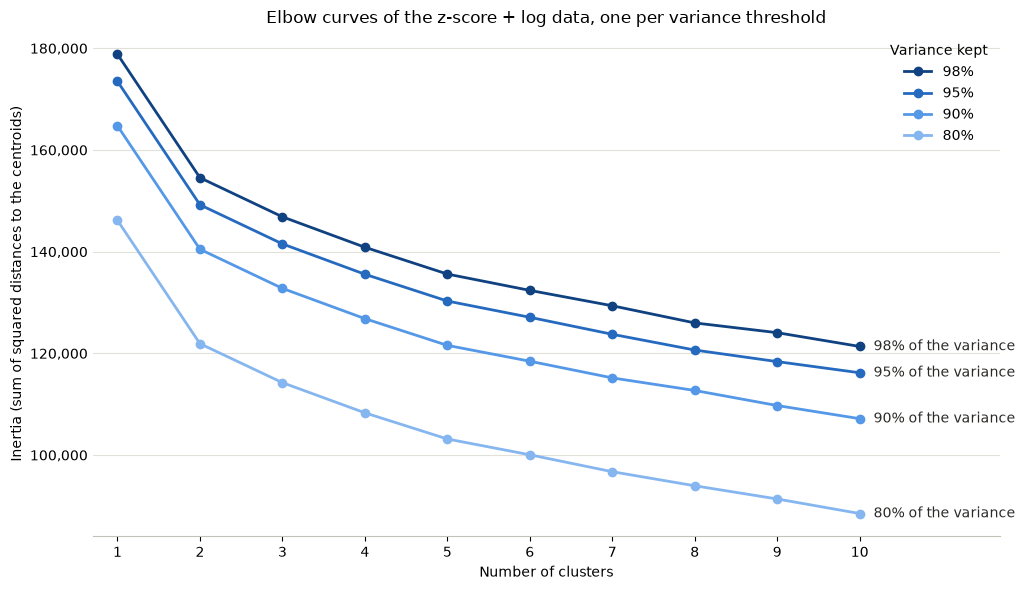

In [5]:
cluster_range = range(1, 11)
inertia = inertia_table(reduced, component_counts, cluster_range)

plot_elbow(inertia, "Elbow curves of the z-score + log data, one per variance threshold")

In [6]:
drop_per_cluster = inertia.pct_change().dropna().mul(-100).round(1)
drop_per_cluster.index.name = "Cluster added"

kept = pd.Series({f"{t:.0%}": cumulative[count - 1] for t, count in component_counts.items()})
height = pd.DataFrame(
    {
        "Inertia with 1 cluster": inertia.loc[1],
        "Compared with 98%": inertia.loc[1] / inertia.loc[1, "98%"],
        "Variance kept compared with 98%": kept / kept["98%"],
    }
)

print("Inertia:")
display(inertia.round(0).astype(int))
print("Percentage drop in inertia when one more cluster is added:")
display(drop_per_cluster)
print("Height of the curves:")
display(height.round(3))

Inertia:


,98%,95%,90%,80%
Clusters,,,,
1,178822,173497,164748,146152
2,154546,149223,140478,121905
3,146852,141531,132782,114240
4,140871,135561,126831,108306
5,135596,130291,121573,103160
6,132388,127094,118456,100054
7,129362,123753,115175,96725
8,125989,120657,112705,93959
9,124069,118379,109738,91364


Percentage drop in inertia when one more cluster is added:


,98%,95%,90%,80%
Cluster added,,,,
2,13.6,14.0,14.7,16.6
3,5.0,5.2,5.5,6.3
4,4.1,4.2,4.5,5.2
5,3.7,3.9,4.1,4.8
6,2.4,2.5,2.6,3.0
7,2.3,2.6,2.8,3.3
8,2.6,2.5,2.1,2.9
9,1.5,1.9,2.6,2.8
10,2.2,1.9,2.4,3.1


Height of the curves:


,Inertia with 1 cluster,Compared with 98%,Variance kept compared with 98%
98%,178821.545,1.000,1.000
95%,173496.800,0.970,0.970
90%,164748.463,0.921,0.921
80%,146152.109,0.817,0.817


#### Interpretation of the elbow curves
- **Meaning of inertia:** take each house, measure the distance to the centroid (the mean point) of its cluster, square it and add everything up. The smaller the total, the more compact the clusters.
- **Always downward:** each new centroid gives some houses a closer center and takes none away, so the total keeps shrinking, at 90% from 164,748 to 107,155. Even random data would show this, so the elbow method only looks at how quickly the gain shrinks.
- **The bend:** the first split stands out, as the second cluster removes 14.7% at 90%. The third, fourth and fifth remove 5.5%, 4.5% and 4.1%. After that the gains are 2.1% to 2.8%. So the main bend comes at 2 clusters, and a smaller step follows after 5 clusters.
- **Lower curves:** the 80% curve starts at 146,152, or 0.817 of the 98% curve. The last table gives the same 0.817 for the variance kept. A single cluster measures exactly the kept variance, so a dataset with fewer components starts lower and stays lower.
- **Height is not quality:** this offset is why only the shape is read here. The percentage table has nearly the same rows for all thresholds: 13.6% to 16.6% for the second cluster and 3.7% to 4.8% for the fifth.

### Silhouette analysis

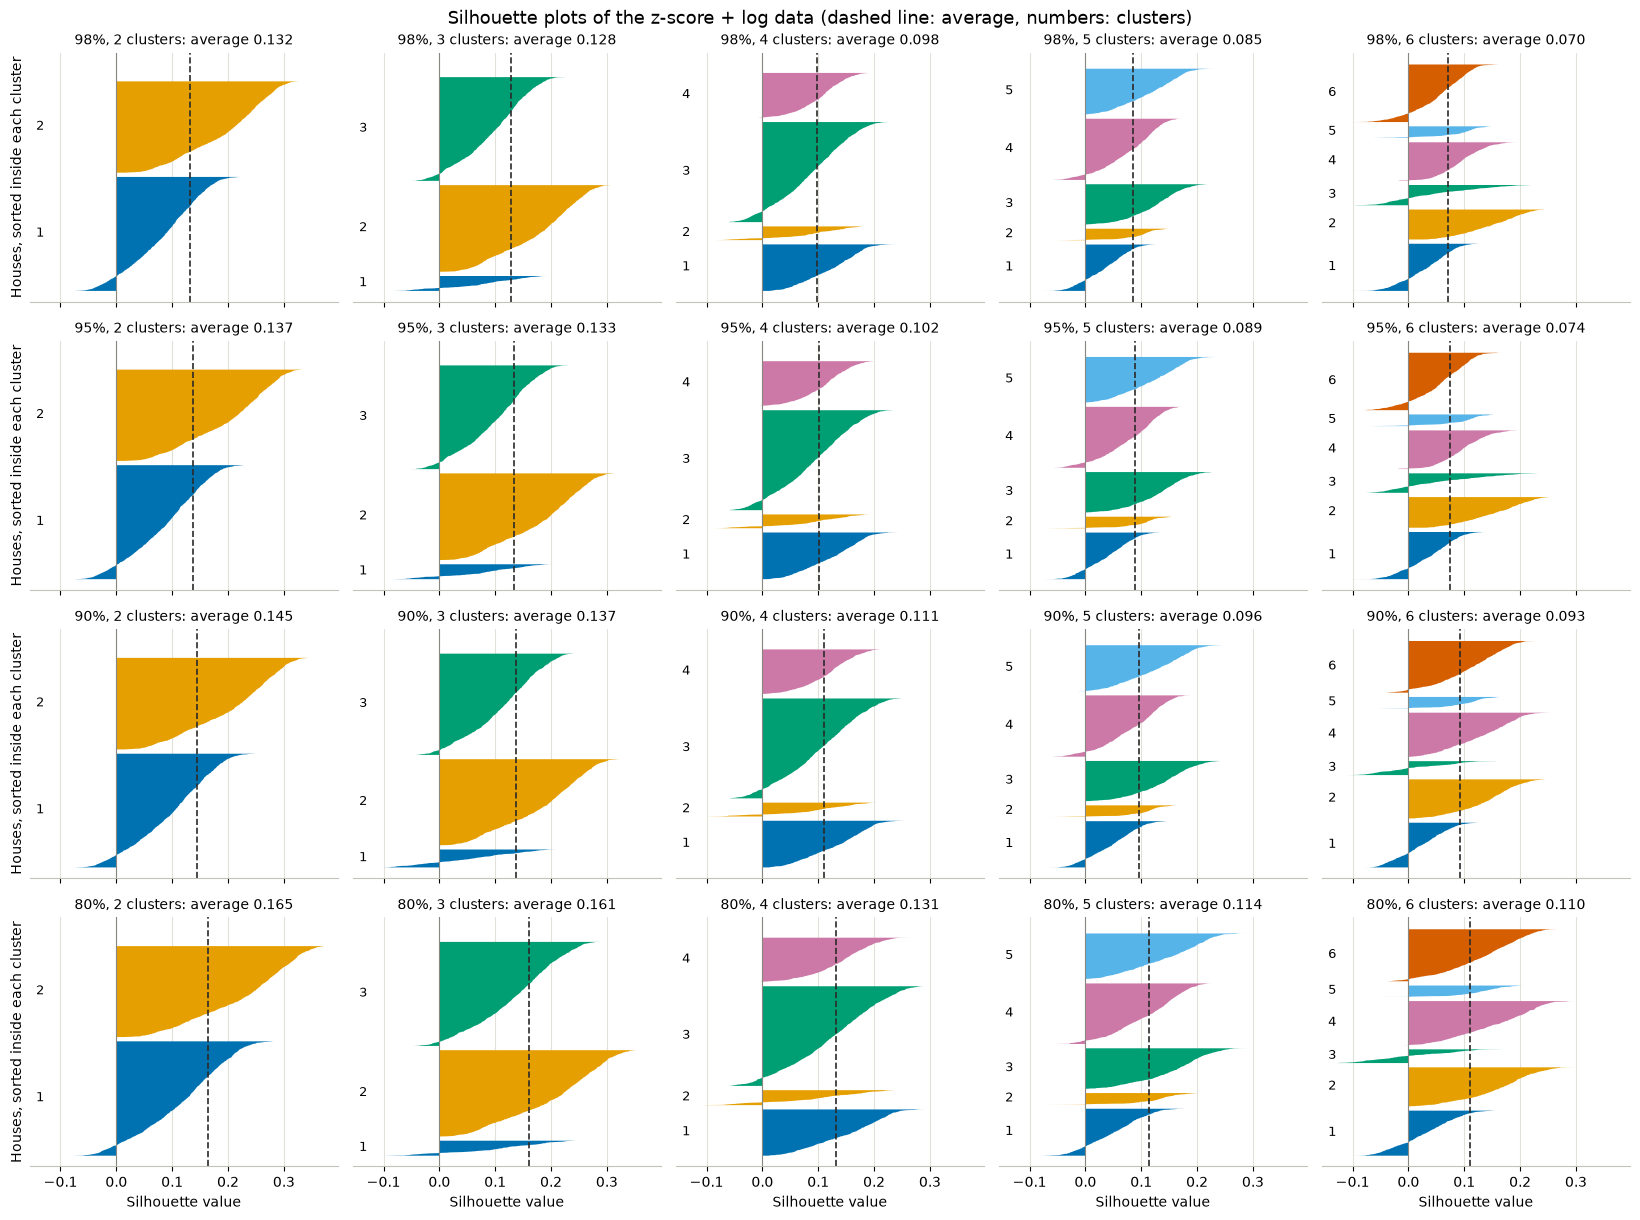

In [7]:
plot_silhouettes(
    reduced,
    component_counts,
    range(2, 7),
    "Silhouette plots of the z-score + log data (dashed line: average, numbers: clusters)",
)

In [8]:
silhouette = silhouette_table(reduced, component_counts, range(2, 9))

print("Average silhouette:")
display(silhouette.round(3))
print("Number of clusters with the highest average silhouette:")
print(silhouette.idxmax().to_string())

Average silhouette:


,98%,95%,90%,80%
Clusters,,,,
2,0.132,0.137,0.145,0.165
3,0.128,0.133,0.137,0.161
4,0.098,0.102,0.111,0.131
5,0.085,0.089,0.096,0.114
6,0.070,0.074,0.093,0.110
7,0.069,0.091,0.087,0.104
8,0.073,0.079,0.083,0.100


Number of clusters with the highest average silhouette:
98%    2
95%    2
90%    2
80%    2


#### Interpretation of the silhouette analysis
- **Definition:** `(b - a) / max(a, b)` per house, with `a` the mean distance to the houses of its own cluster and `b` the mean distance to the houses of the closest other one. A value near 1 means a clear place, a value near 0 a place on a border, and a value below 0 suggests the wrong cluster.
- **Figure:** the shapes are the clusters with their houses sorted by value, their height is the cluster size and the dashed line is the average of the model.
- **Level of the scores:** the averages stay between 0.069 and 0.165. With values this low, the distance to the own cluster is nearly the same as to the next one, so clusters overlap a lot. The data looks like one large cloud that k-means cuts into pieces, with no empty space between them.
- **Trend with more clusters:** the highest average is at 2 clusters at each threshold, and at 90% it keeps falling: 0.145, 0.137, 0.111, 0.096, 0.093, 0.087 and 0.083 from 2 to 8 clusters. This trend speaks clearly for few clusters.
- **Thin clusters:** with 5 clusters the small cluster 2 is visible in every row. With 2 clusters, cluster 1 has a clear part below 0, so even the best-scoring model has houses near the border.
- **Fewer components:** the average at 5 clusters goes up from 0.085 at 98% to 0.114 at 80%, because fewer small components blur the distances. Whether the groups change is checked with the final models.

### Choice of the number of clusters

In [9]:
test_threshold = 0.90
test_data = reduced[:, : component_counts[test_threshold]]
seeds = range(6)

rows = []
for k in range(2, 8):
    runs = [KMeans(n_clusters=k, n_init=N_INIT, random_state=seed).fit_predict(test_data) for seed in seeds]
    pair_scores = [adjusted_rand_score(first, second) for first, second in combinations(runs, 2)]
    rows.append(
        {
            "Clusters": k,
            "Seed pairs": len(pair_scores),
            "Mean agreement": np.mean(pair_scores),
            "Lowest agreement": np.min(pair_scores),
            "Inertia drop (%)": drop_per_cluster.loc[k, "90%"],
            "Average silhouette": silhouette.loc[k, "90%"],
            "Cluster sizes (seed 0)": sorted(np.bincount(runs[0]).tolist()),
        }
    )

choice = pd.DataFrame(rows).set_index("Clusters")
with pd.option_context("display.max_colwidth", None):
    display(choice.round(3))

,Seed pairs,Mean agreement,Lowest agreement,Inertia drop (%),Average silhouette,Cluster sizes (seed 0)
Clusters,,,,,,
2,15,0.997,0.995,14.7,0.145,"[1300, 1623]"
3,15,0.959,0.903,5.5,0.137,"[242, 1225, 1456]"
4,15,0.917,0.853,4.5,0.111,"[214, 626, 666, 1417]"
5,15,0.992,0.985,4.1,0.096,"[166, 574, 649, 670, 864]"
6,15,0.867,0.751,2.6,0.093,"[166, 299, 424, 554, 666, 814]"
7,15,0.702,0.571,2.8,0.087,"[82, 146, 193, 536, 549, 591, 826]"


In [10]:
n_clusters = 5

rows = []
for seed in [*seeds, SEED]:
    model = KMeans(n_clusters=n_clusters, n_init=N_INIT, random_state=seed).fit(test_data)
    rows.append({"Seed": seed, "Inertia": model.inertia_, "Cluster sizes": sorted(np.bincount(model.labels_).tolist())})

print(f"Chosen number of clusters: {n_clusters}")
print(f"Runs at {test_threshold:.0%} of the variance with each seed:")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("Seed").round(1))

Chosen number of clusters: 5
Runs at 90% of the variance with each seed:


,Inertia,Cluster sizes
Seed,,
0,121573.0,"[166, 574, 649, 670, 864]"
1,121573.0,"[166, 572, 651, 671, 863]"
2,121572.8,"[166, 574, 649, 676, 858]"
3,121573.0,"[166, 574, 649, 670, 864]"
4,121573.1,"[166, 574, 651, 673, 859]"
5,121572.7,"[166, 573, 650, 678, 856]"
42,121573.4,"[165, 572, 654, 659, 873]"


#### Interpretation of the number of clusters
- **What was tried:** for 2 to 7 clusters at 90%, six seeds gave six different random starts. The 15 pairs of runs were scored with the **adjusted Rand index**, which reads 1 if both runs form the same groups, under any numbering, and about 0 if the match is no better than chance.
- **What came out:** the mean agreement is 0.997 for 2 clusters, falls to 0.959 and 0.917 for 3 and 4, and rises to 0.992 for 5, with a lowest pair of 0.985. For 6 and 7 clusters it is 0.867 and 0.702.
- **Choice:** 5 clusters.
    - **Stability:** nearly as high as with 2 clusters, and above 3 and 4. All seven runs of the seed table lie between 121,572.7 and 121,573.4, so they reach practically the same solution.
    - **Elbow:** the gain falls from 4.1% to 2.6% after the fifth cluster.
    - **Detail:** 2 clusters give two halves of 1,300 and 1,623 houses, which is a coarse picture.
    - **One number for all:** with the same number as notebooks 08, 08.1 and 08.2, the notebooks can be compared directly.
- **Evidence against it:** the silhouette is clearly better for few clusters, with 0.145 at 2 and 0.137 at 3 against 0.096 at 5. The sharpest bend of the elbow is also at 2 clusters. This data on its own would point to 2 clusters rather than 5.
- **Rejected:** 2 clusters are too coarse, 3 and 4 clusters are less stable than 5, and with 6 or 7 clusters the seed starts to decide the result.

### Final models and cluster scatter plots

In [11]:
models = fit_models(reduced, component_counts, n_clusters)
labels_at_98 = models[0.98].labels_

rows = []
for threshold, model in models.items():
    count = component_counts[threshold]
    values = silhouette_samples(reduced[:, :count], model.labels_)
    sizes = np.bincount(model.labels_)
    rows.append(
        {
            "Variance kept": f"{threshold:.0%}",
            "Components": count,
            **{f"Cluster {number}": size for number, size in enumerate(sizes, start=1)},
            "Inertia": model.inertia_,
            "Average silhouette": values.mean(),
            "Negative silhouette": (values < 0).mean(),
            "Houses not in their 98% cluster": (model.labels_ != labels_at_98).sum(),
        }
    )

final_models = pd.DataFrame(rows).set_index("Variance kept")
display(final_models.round(3))

,Components,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Inertia,Average silhouette,Negative silhouette,Houses not in their 98% cluster
Variance kept,,,,,,,,,,
98%,84,661,165,573,872,652,135596.484,0.085,0.085,0
95%,61,664,166,575,868,650,130290.979,0.089,0.079,10
90%,45,659,165,572,873,654,121573.395,0.096,0.070,3
80%,29,669,163,577,863,651,103160.403,0.114,0.066,37


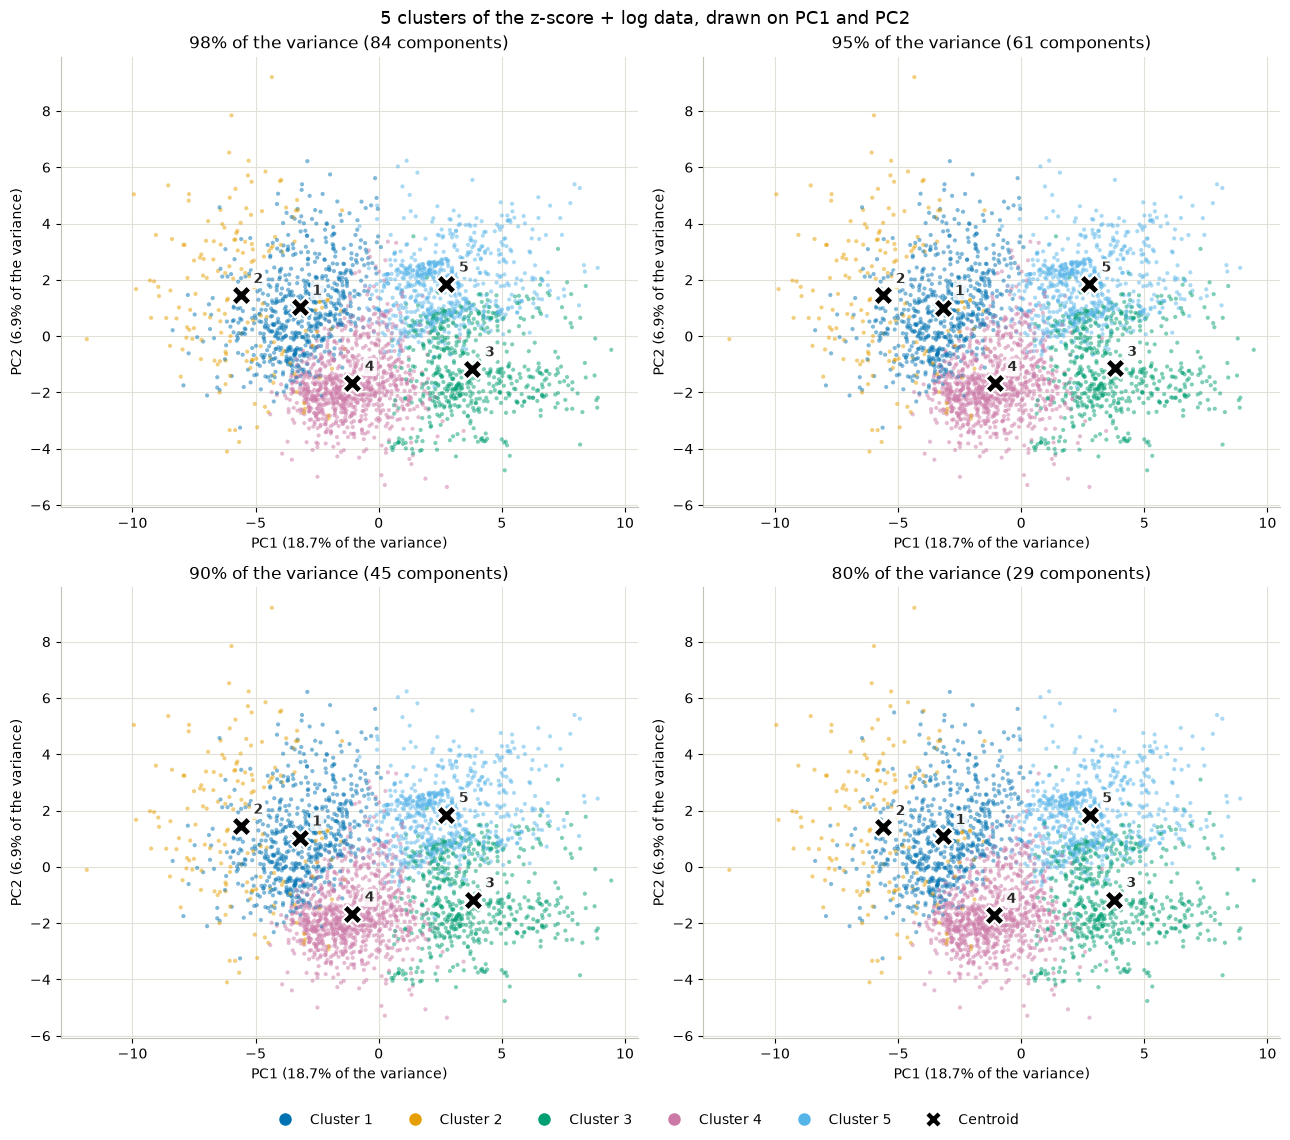

In [12]:
panels = {
    f"{threshold:.0%} of the variance ({component_counts[threshold]} components)": (pca, reduced, model)
    for threshold, model in models.items()
}
plot_clusters(panels, f"{n_clusters} clusters of the z-score + log data, drawn on PC1 and PC2")

In [13]:
threshold_agreement = agreement_table({f"{t:.0%}": model.labels_ for t, model in models.items()})
pair_scores = threshold_agreement.to_numpy()[np.triu_indices(len(threshold_agreement), k=1)]

centroid_shift = max(
    np.abs(model.cluster_centers_[:, :2] - models[0.98].cluster_centers_[:, :2]).max() for model in models.values()
)
visible = pd.Series({f"{t:.0%}": shares[:2].sum() / cumulative[count - 1] for t, count in component_counts.items()})

print("Adjusted Rand index between the thresholds:")
display(threshold_agreement.round(3))
print(f"Lowest agreement between two thresholds: {pair_scores.min():.3f}")
print(f"Largest move of a centroid on PC1 or PC2 compared with 98%: {centroid_shift:.3f}")
print(f"Standard deviation of the houses on PC1 / PC2: {reduced[:, 0].std():.3f} / {reduced[:, 1].std():.3f}")
print("Share of the kept variance that PC1 and PC2 show:")
print(visible.map("{:.1%}".format).to_string())

Adjusted Rand index between the thresholds:


,98%,95%,90%,80%
98%,1.000,0.991,0.997,0.965
95%,0.991,1.000,0.988,0.966
90%,0.997,0.988,1.000,0.965
80%,0.965,0.966,0.965,1.000


Lowest agreement between two thresholds: 0.965
Largest move of a centroid on PC1 or PC2 compared with 98%: 0.053
Standard deviation of the houses on PC1 / PC2: 3.414 / 2.075
Share of the kept variance that PC1 and PC2 show:
98%    26.1%
95%    26.9%
90%    28.3%
80%    31.9%


#### Interpretation of the final models
- **Are there differences?** The three higher thresholds give almost the same model: 10 houses change at 95% and only 3 at 90%, and their agreement is at least 0.988. The 80% model stands apart a little, with 37 houses in another cluster and an agreement of 0.965 or 0.966 with the others. The size of a cluster changes by at most 10 houses across the thresholds (clusters 1 and 4).
- **Same picture each time:** the first two columns of the reduced data do not depend on the threshold, so the dots do not move between panels. The centroids shift by 0.053 at most, against a spread of 3.414 on PC1 and 2.075 on PC2.
- **Why:** components after the first 29 hold 18 percentage points of the variance, split over 55 components, so each one has only a small say in which centroid is nearest. The cut to 29 components removes enough to move 37 houses at the borders, while the cuts to 61 and 45 hardly matter.
- **Scores:** inertia falls from 135,596 to 103,160 and the average silhouette rises from 0.085 to 0.114, while negative silhouettes go from 8.5% to 6.6% of the houses. Since membership is nearly constant, this reflects the smaller number of dimensions.
- **Overlapping colors:** PC1 and PC2 show between 26.1% and 31.9% of the kept variance, and k-means saw all of it. Houses that seem to mix on the screen are often separated by components that cannot be drawn here. This is most visible for small cluster 2, which spreads through cluster 1 on the left of the panels.